<a href="https://colab.research.google.com/github/Sayed-Hossein-Hosseini/Fuzzy_Logic_For_Studen_Academi-Succes_Prediction/blob/master/Fuzzy_Logic_For_Studen_Academi_Succes_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Fuzzy Logic For Studen Academi Succes Prediction**

## **Libraries**

In [1]:
!pip install kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## **Data Preprocessing and Exploration**

### **Download Dataset**

In [2]:
# Download latest version
source_path = kagglehub.dataset_download("thedevastator/higher-education-predictors-of-student-retention")

print("Path to dataset files:", source_path)

# /kaggle/input/higher-education-predictors-of-student-retention/dataset.csv

Path to dataset files: /kaggle/input/higher-education-predictors-of-student-retention


### **Load Data**

In [3]:
# Optional settings for plot display
# You might need to install specific fonts if you want special characters,
# but for standard English, defaults are usually fine.
# plt.rcParams['font.family'] = 'Your Preferred Font' # e.g., 'Arial' or 'Times New Roman' if needed
plt.rcParams['figure.figsize'] = (10, 6) # Default figure size

# --- Load Data ---
file_path = '/kaggle/input/higher-education-predictors-of-student-retention/dataset.csv'
try:
    df = pd.read_csv(file_path)
    print("dataset.csv file loaded successfully.")
    print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")
except FileNotFoundError:
    print(f"Error: File {file_path} not found. Please check the file path.")
    exit() # Do not continue if the file is not found

dataset.csv file loaded successfully.
Number of rows: 4424, Number of columns: 35


### **Data Description**

In [4]:
print("\n--- Display first 5 rows ---")
print(df.head())

print("\n--- DataFrame General Information (Column Types and Non-Null Values) ---")
# Pay attention to Dtype and Non-Null Count. If Non-Null Count is less than the total number of rows, it means we have missing values.
# Also, check the data types (Dtype) (object means string, int64 means integer, float64 means floating-point number).
df.info()

print("\n--- Descriptive Statistics for Numerical Columns ---")
# This section gives us a general overview of the value range (min, max), mean, median (50%), and dispersion (std).
print(df.describe())


--- Display first 5 rows ---
   Marital status  Application mode  Application order  Course  \
0               1                 8                  5       2   
1               1                 6                  1      11   
2               1                 1                  5       5   
3               1                 8                  2      15   
4               2                12                  1       3   

   Daytime/evening attendance  Previous qualification  Nacionality  \
0                           1                       1            1   
1                           1                       1            1   
2                           1                       1            1   
3                           1                       1            1   
4                           0                       1            1   

   Mother's qualification  Father's qualification  Mother's occupation  ...  \
0                      13                      10                    6  .

### **Check Formatting Issues**

In [10]:
print("----")
print(f"Number of Duplicated Rows: {df.duplicated().sum()}")
print("--------")
print("Unique Values Number in Each Column:")
print(df.nunique())

----
0
----
Marital status                                      6
Application mode                                   18
Application order                                   8
Course                                             17
Daytime/evening attendance                          2
Previous qualification                             17
Nacionality                                        21
Mother's qualification                             29
Father's qualification                             34
Mother's occupation                                32
Father's occupation                                46
Displaced                                           2
Educational special needs                           2
Debtor                                              2
Tuition fees up to date                             2
Gender                                              2
Scholarship holder                                  2
Age at enrollment                                  46
International   

### **Missing Values**

In [6]:
# --- Check Missing Values ---
print("\n--- Checking missing values in each column ---")
missing_values = df.isnull().sum()
print("Columns with missing values:")
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("\n--> Result: No missing values found in the dataset. No cleaning needed for this part.")
else:
    print("\n--> Warning: Missing values found!")
    # A decision must be made here:
    # 1. Remove rows: df.dropna(inplace=True) (if the count is small)
    # 2. Fill with mean/median/mode: df['column_name'].fillna(df['column_name'].median(), inplace=True)
    # For now, since we don't have missing values, we take no action.

# --- Check and Convert Data Types (If Necessary) ---
print("\n--- Checking Data Types ---")
print("Based on the df.info() output, the column data types seem appropriate (mostly int or float).")
# If a column needed conversion, e.g., from object to number:
# try:
#     df['suspicious_column_name'] = pd.to_numeric(df['suspicious_column_name'], errors='coerce')
#     # errors='coerce' will turn non-convertible values into NaN
#     # Then NaNs can be handled (e.g., removal or imputation)
#     # df.dropna(subset=['suspicious_column_name'], inplace=True)
# except KeyError:
#     print("Suspicious column for type conversion does not exist.")


--- Checking missing values in each column ---
Columns with missing values:
Series([], dtype: int64)

--> Result: No missing values found in the dataset. No cleaning needed for this part.

--- Checking Data Types ---
Based on the df.info() output, the column data types seem appropriate (mostly int or float).


### **Target Variable Distribution**

In [7]:
# --- Check Target Variable Distribution ---
print("\n--- Distribution of Target Variable Classes ---")
target_distribution = df['Target'].value_counts()
print(target_distribution)

print("\n--- Percentage Distribution of Target Classes ---")
print(df['Target'].value_counts(normalize=True) * 100)
# Note the proportions. If one class is much less frequent than others, we have imbalance.
# This imbalance can affect the model's performance and evaluation.


--- Distribution of Target Variable Classes ---
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

--- Percentage Distribution of Target Classes ---
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


### **Data Visualization (EDA)**


--- Starting Data Visualization (EDA) ---


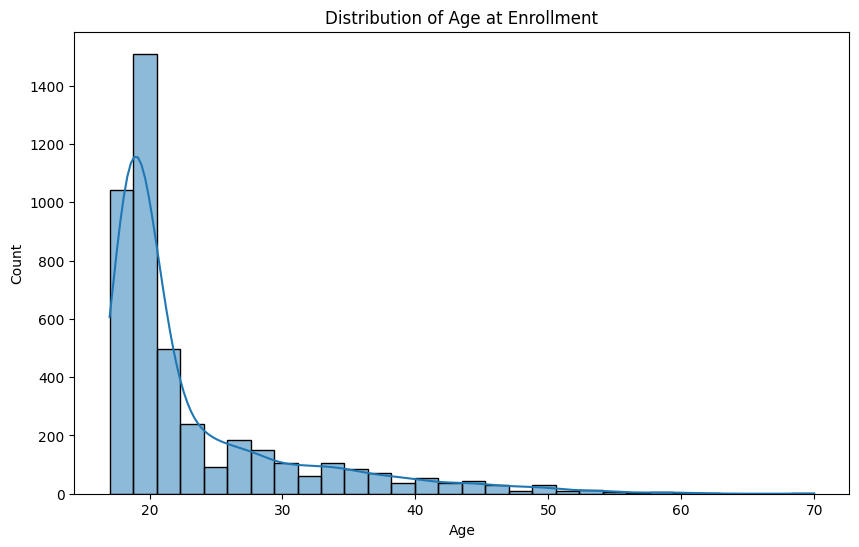

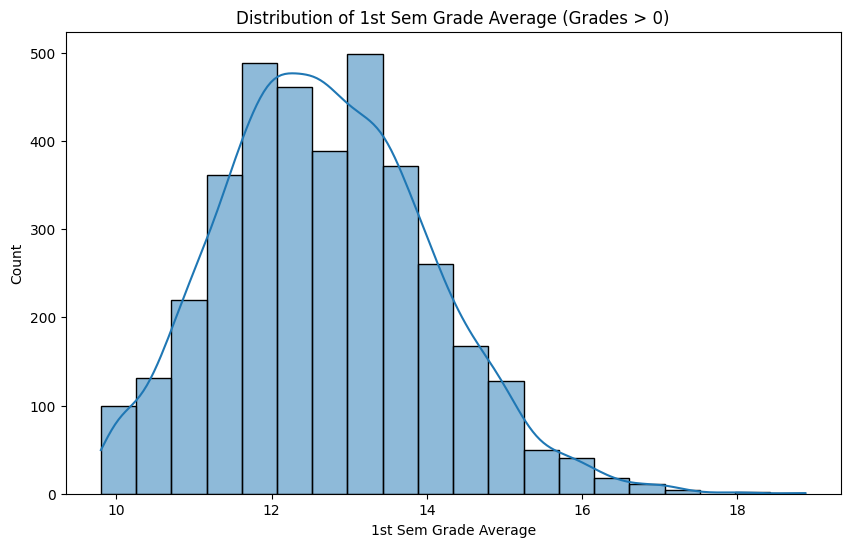

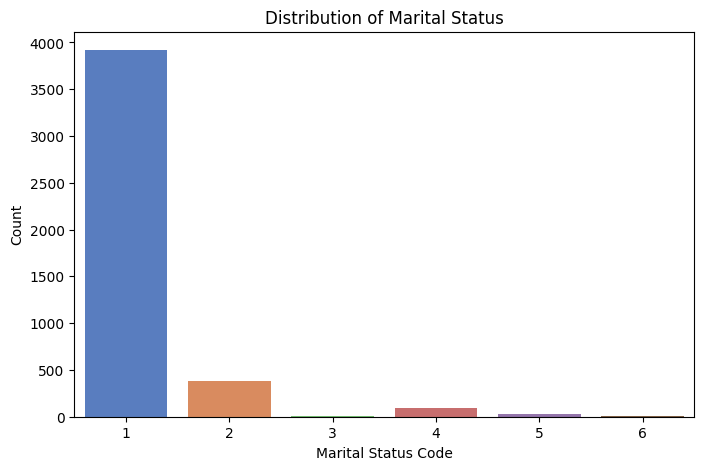

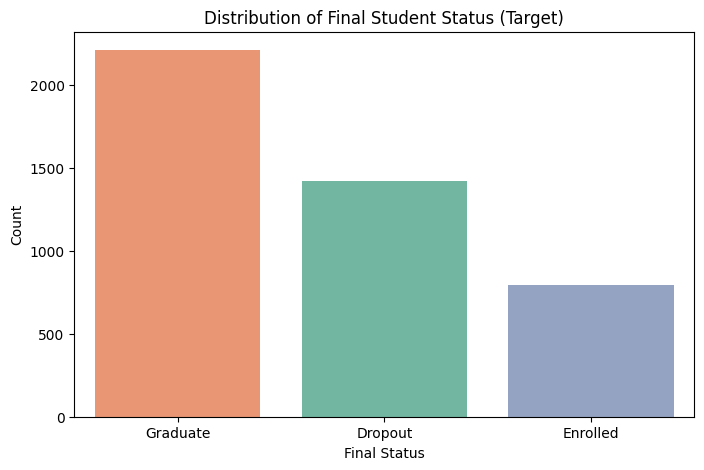

--- End of Data Visualization ---


In [ ]:
# --- Data Visualization (Part of EDA) ---
print("\n--- Starting Data Visualization (EDA) ---")

# 1. Distribution of Age at Enrollment (Continuous Feature)
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age at enrollment', kde=True, bins=30)
plt.title('Distribution of Age at Enrollment')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# 2. Distribution of 1st Semester Grade Average (Continuous Feature)
# Grades of 0 might have a special meaning (e.g., course not taken or grade not registered)
# We can filter them out or investigate further. For now, we filter.
grades_sem1_valid = df[df['Curricular units 1st sem (grade)'] > 0]['Curricular units 1st sem (grade)']
if not grades_sem1_valid.empty:
    plt.figure(figsize=(10, 6))
    sns.histplot(grades_sem1_valid, kde=True, bins=20)
    plt.title('Distribution of 1st Sem Grade Average (Grades > 0)')
    plt.xlabel('1st Sem Grade Average')
    plt.ylabel('Count')
    plt.show()
else:
    print("No valid data (greater than zero) found for 1st semester grades to plot histogram.")

# 3. Count Plot for Marital Status (Categorical Feature)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Marital status', palette='muted', hue='Marital status', legend=False)
plt.title('Distribution of Marital Status')
plt.xlabel('Marital Status Code')
plt.ylabel('Count')
# If you know the meaning of the codes, you can add labels:
# plt.xticks(ticks=[...], labels=[...])
plt.show()

# 4. Distribution of Target Variable
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Target', palette='Set2', order=df['Target'].value_counts().index, hue='Target', legend=False) # Order by frequency
plt.title('Distribution of Final Student Status (Target)')
plt.xlabel('Final Status')
plt.ylabel('Count')
plt.show()

print("--- End of Data Visualization ---")

### **Train/Test Split**

In [ ]:
# --- Separate Features (X) and Target (y) ---
print("\n--- Separating Features and Target Variable ---")
if 'Target' in df.columns:
    X = df.drop('Target', axis=1) # All columns except Target
    y = df['Target']               # Only the Target column
    print(f"Features (X) separated with shape {X.shape}.")
    print(f"Target (y) separated with shape {y.shape}.")
else:
    print("Error: 'Target' column not found in DataFrame.")
    exit()

# --- Split Data into Training and Testing Sets ---
print("\n--- Splitting data into Training (80%) and Testing (20%) sets ---")
# stratify=y is important to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Number of training samples: {X_train.shape[0]}")
print(f"Number of testing samples: {X_test.shape[0]}")

print("\n--- Checking target class distribution in the training set ---")
print(y_train.value_counts(normalize=True) * 100)
print("\n--- Checking target class distribution in the testing set ---")
print(y_test.value_counts(normalize=True) * 100)
print("--> Percentage distribution of classes should be very similar in both sets.")

# Save the split data for later stages (optional)
# X_train.to_csv('X_train.csv', index=False)
# X_test.to_csv('X_test.csv', index=False)
# y_train.to_csv('y_train.csv', index=False, header=True)
# y_test.to_csv('y_test.csv', index=False, header=True)
# print("\nTraining and testing data saved.")


--- Separating Features and Target Variable ---
Features (X) separated with shape (4424, 34).
Target (y) separated with shape (4424,).

--- Splitting data into Training (80%) and Testing (20%) sets ---
Number of training samples: 3539
Number of testing samples: 885

--- Checking target class distribution in the training set ---
Target
Graduate    49.929359
Dropout     32.127720
Enrolled    17.942922
Name: proportion, dtype: float64

--- Checking target class distribution in the testing set ---
Target
Graduate    49.943503
Dropout     32.090395
Enrolled    17.966102
Name: proportion, dtype: float64
--> Percentage distribution of classes should be very similar in both sets.


## **Feature Fuzzification**

### **Extracting Continuous and Discrete Features**

In [ ]:
# (Assuming df, X_train, y_train, ... exist from the previous phase)

# Identify continuous and categorical columns based on name and data type
# This list might need finer tuning, but it's a good starting point.
all_features = X_train.columns.tolist()

# Numerical features likely to be treated as continuous (may need more domain knowledge)
# Includes Grades, Counts, Economic Indicators
continuous_features = [
    'Age at enrollment',
    'Previous qualification', # Added - This is also a grade
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

# Consider the remaining features as categorical or binary
categorical_features = [col for col in all_features if col not in continuous_features]

print(f"Number of continuous features identified: {len(continuous_features)}")
print(f"Number of categorical/binary features identified: {len(categorical_features)}")
# print("Categorical features:", categorical_features) # For review

Number of continuous features identified: 17
Number of categorical/binary features identified: 17


### **Triangular Function**

In [ ]:
def triangular_mf(x, a, b, c):
    """
    Calculates the membership degree for a triangular function with points a, b, c (a <= b <= c).
    """
    # Ensure points are ordered to avoid division by zero or logic errors
    if not (a <= b <= c):
        # print(f"Warning: Points out of order ({a}, {b}, {c}) for value {x}. Returning 0.")
        # Alternatively, sort the points:
        # points = sorted([a, b, c])
        # a, b, c = points[0], points[1], points[2]
        # For now, assume points are ordered or handled during parameter definition.
        return 0.0 # Or other appropriate value

    # Handle cases where a=b or b=c to prevent division by zero
    if b == a and b == c: # If all points are the same
        return 1.0 if x == b else 0.0
    elif b == a: # Vertical left edge (right triangle)
         if x <= a: return 1.0 # Or 0.0 depending on edge definition
         if x > c: return 0.0
         # Ensure c > b (which is a here) before dividing
         return max(0.0, (c - x) / (c - b)) if c > b else (1.0 if x <= c else 0.0)
    elif b == c: # Vertical right edge (left triangle)
        if x >= c: return 1.0 # Or 0.0 depending on edge definition
        if x < a: return 0.0
        # Ensure b > a before dividing
        return max(0.0, (x - a) / (b - a)) if b > a else (1.0 if x >= a else 0.0)
    else: # Standard triangle case
        # Ensure denominators are not zero before division
        term1 = (x - a) / (b - a) if (b - a) != 0 else (1.0 if x >= a else 0.0)
        term2 = (c - x) / (c - b) if (c - b) != 0 else (1.0 if x <= c else 0.0)
        return max(0.0, min(term1, term2))


# --- Test the triangular function ---
print("\n--- Testing Triangular Function ---")
print(f"Membership of value 3 in triangle (1, 5, 10): {triangular_mf(3, 1, 5, 10):.2f}") # Should be between 0 and 1
print(f"Membership of value 5 in triangle (1, 5, 10): {triangular_mf(5, 1, 5, 10):.2f}") # Should be 1
print(f"Membership of value 8 in triangle (1, 5, 10): {triangular_mf(8, 1, 5, 10):.2f}") # Should be between 0 and 1
print(f"Membership of value 12 in triangle (1, 5, 10): {triangular_mf(12, 1, 5, 10):.2f}") # Should be 0


--- Testing Triangular Function ---
Membership of value 3 in triangle (1, 5, 10): 0.50
Membership of value 5 in triangle (1, 5, 10): 1.00
Membership of value 8 in triangle (1, 5, 10): 0.40
Membership of value 12 in triangle (1, 5, 10): 0.00


### **Membership Function Parameters for Continuous Features**

In [ ]:
# --- Define Membership Function Parameters for Continuous Features ---
print("\n--- Calculating Membership Function Parameters for Continuous Features (based on Training Data) ---")

mf_params_continuous = {}

for feature in continuous_features:
    # Calculate necessary values from the training data
    min_val = X_train[feature].min()
    # Use median (50th percentile) for the peak of 'Medium'
    p50_val = X_train[feature].median()
    max_val = X_train[feature].max()

    # Handle cases where min, median, and max are identical (only one unique value)
    if min_val == p50_val == max_val:
        mf_params_continuous[feature] = {
            'Medium': (min_val, min_val, min_val) # Only one possible value
        }
        # print(f"Warning: Feature '{feature}' has only one unique value: {min_val}")
    # Handle cases where median coincides with min or max (results in 2 sets)
    elif min_val == p50_val:
         mf_params_continuous[feature] = {
            'Low': (min_val, min_val, max_val), # Peak at min, ends at max
            'High':(min_val, max_val, max_val) # Starts at min, peaks at max
         }
         # print(f"Warning: Feature '{feature}' has median equal to minimum. Using 2 sets.")
    elif p50_val == max_val:
         mf_params_continuous[feature] = {
            'Low': (min_val, min_val, max_val), # Peak at min, ends at max
            'High':(min_val, max_val, max_val) # Starts at min, peaks at max
         }
         # print(f"Warning: Feature '{feature}' has median equal to maximum. Using 2 sets.")
    else:
        # Define points for 3 triangular functions: Low, Medium, High
        # Low: Peaks at min, ends at p50
        # Medium: Starts at min, peaks at p50, ends at max
        # High: Starts at p50, peaks at max
        mf_params_continuous[feature] = {
            'Low': (min_val, min_val, p50_val),
            'Medium': (min_val, p50_val, max_val),
            'High': (p50_val, max_val, max_val)
        }

print("\nCalculated parameters for the first few features:")
for i, (feature, params) in enumerate(mf_params_continuous.items()):
    if i < 3: # Display first 3
        print(f"  {feature}: {params}")


--- Calculating Membership Function Parameters for Continuous Features (based on Training Data) ---

Calculated parameters for the first few features:
  Age at enrollment: {'Low': (17, 17, 20.0), 'Medium': (17, 20.0, 70), 'High': (20.0, 70, 70)}
  Previous qualification: {'Low': (1, 1, 17), 'High': (1, 17, 17)}
  Curricular units 1st sem (credited): {'Low': (0, 0, 20), 'High': (0, 20, 20)}


### **Write Fuzzification Function for Continuous Features**

In [ ]:
def fuzzify_continuous(value, feature_name, params_dict):
    """
    Fuzzifies a continuous value and returns membership degrees for each fuzzy set.
    """
    memberships = {}
    if feature_name in params_dict:
        feature_params = params_dict[feature_name]
        for set_name, points in feature_params.items():
            memberships[set_name] = triangular_mf(value, points[0], points[1], points[2])
    else:
        # If parameters weren't defined for this feature (should not happen)
        print(f"Warning: Parameters not found for continuous feature '{feature_name}'.")
        memberships = {} # Or other default
    return memberships

# --- Test Continuous Fuzzification Function ---
print("\n--- Testing Continuous Fuzzification for Age = 20 ---")
age_test = 20
age_membership = fuzzify_continuous(age_test, 'Age at enrollment', mf_params_continuous)
print(f"Membership degrees for Age {age_test}: {age_membership}")


--- Testing Continuous Fuzzification for Age = 20 ---
Membership degrees for Age 20: {'Low': 0.0, 'Medium': 1.0, 'High': 0.0}


### **Define Labels and Fuzzification Function for Categorical/Binary Features**

In [ ]:
# --- Extract Unique Values for Categorical Features (from Training Data) ---
print("\n--- Extracting Unique Values for Categorical/Binary Features ---")
categorical_unique_values = {}
for feature in categorical_features:
    unique_vals = X_train[feature].unique()
    categorical_unique_values[feature] = sorted(unique_vals) # Sorting for consistency

# print("\nUnique values for the first few categorical features:")
# for i, (feature, values) in enumerate(categorical_unique_values.items()):
#     if i < 3:
#         print(f"  {feature}: {values}")

def fuzzify_categorical(value, feature_name, unique_values_dict):
    """
    Fuzzifies a categorical value (Singleton method).
    Creates a fuzzy label for each possible value.
    """
    memberships = {}
    if feature_name in unique_values_dict:
        possible_values = unique_values_dict[feature_name]
        for val in possible_values:
            # Create label name like 'FeatureName_Value'
            label_name = f"{feature_name}_{val}"
            memberships[label_name] = 1.0 if value == val else 0.0
    else:
        print(f"Warning: Unique values not found for categorical feature '{feature_name}'.")
        memberships = {}
    return memberships

# --- Test Categorical Fuzzification Function ---
print("\n--- Testing Categorical Fuzzification for Marital status = 1 ---")
marital_test = 1
marital_membership = fuzzify_categorical(marital_test, 'Marital status', categorical_unique_values)
print(f"Membership degrees for Marital status {marital_test}:")
# Displaying a limited output for readability
limited_output = {k: v for k, v in marital_membership.items() if v > 0 or k.endswith('_0') or k.endswith('_1') or k.endswith('_2')}
print(limited_output)

print("\n--- Testing Categorical Fuzzification for Scholarship holder = 0 ---")
scholarship_test = 0
scholarship_membership = fuzzify_categorical(scholarship_test, 'Scholarship holder', categorical_unique_values)
print(f"Membership degrees for Scholarship holder {scholarship_test}: {scholarship_membership}")


--- Extracting Unique Values for Categorical/Binary Features ---

--- Testing Categorical Fuzzification for Marital status = 1 ---
Membership degrees for Marital status 1:
{'Marital status_1': 1.0, 'Marital status_2': 0.0}

--- Testing Categorical Fuzzification for Scholarship holder = 0 ---
Membership degrees for Scholarship holder 0: {'Scholarship holder_0': 1.0, 'Scholarship holder_1': 0.0}


### **Comprehensive Fuzzification Function for a Full Instance**

In [ ]:
def fuzzify_instance(instance_row, cont_params, cat_unique_vals):
    """
    Fuzzifies a complete row (instance) from the DataFrame.
    """
    fuzzy_representation = {}
    for feature_name, crisp_value in instance_row.items():
        if feature_name in cont_params:
            # Fuzzify continuous feature
            memberships = fuzzify_continuous(crisp_value, feature_name, cont_params)
            # Add feature name prefix to labels to avoid clashes (e.g., Low_Age, Low_Grade)
            for set_name, membership_degree in memberships.items():
                fuzzy_representation[f"{feature_name}_{set_name}"] = membership_degree
        elif feature_name in cat_unique_vals:
            # Fuzzify categorical/binary feature
            memberships = fuzzify_categorical(crisp_value, feature_name, cat_unique_vals)
            # Label names are already created in fuzzify_categorical
            fuzzy_representation.update(memberships)
        # else: # If feature is neither continuous nor categorical (should not happen)
            # print(f"Warning: Feature '{feature_name}' not found in continuous or categorical definitions.")
            # pass
    return fuzzy_representation

# --- Test Comprehensive Fuzzification on the first training instance ---
print("\n--- Testing Comprehensive Fuzzification on the first training sample ---")
sample_instance = X_train.iloc[0]
fuzzy_sample = fuzzify_instance(sample_instance, mf_params_continuous, categorical_unique_values)
print("Fuzzified sample (only non-zero values shown for brevity):")
non_zero_fuzzy_sample = {k: v for k, v in fuzzy_sample.items() if v > 0}
import json # For pretty printing the dictionary
print(json.dumps(non_zero_fuzzy_sample, indent=2))


--- Testing Comprehensive Fuzzification on the first training sample ---
Fuzzified sample (only non-zero values shown for brevity):
{
  "Marital status_1": 1.0,
  "Application mode_14": 1.0,
  "Application order_1": 1.0,
  "Course_10": 1.0,
  "Daytime/evening attendance_1": 1.0,
  "Previous qualification_Low": 0.1875,
  "Previous qualification_High": 0.8125,
  "Nacionality_1": 1.0,
  "Mother's qualification_2": 1.0,
  "Father's qualification_1": 1.0,
  "Mother's occupation_2": 1.0,
  "Father's occupation_3": 1.0,
  "Displaced_0": 1.0,
  "Educational special needs_0": 1.0,
  "Debtor_0": 1.0,
  "Tuition fees up to date_1": 1.0,
  "Gender_1": 1.0,
  "Scholarship holder_0": 1.0,
  "Age at enrollment_Medium": 0.98,
  "Age at enrollment_High": 0.02,
  "International_0": 1.0,
  "Curricular units 1st sem (credited)_Low": 0.55,
  "Curricular units 1st sem (credited)_High": 0.45,
  "Curricular units 1st sem (enrolled)_Medium": 0.75,
  "Curricular units 1st sem (enrolled)_High": 0.25,
  "Curricu

### **Plot Membership Functions (As Required by the Project)**


--- Plotting Membership Functions ---


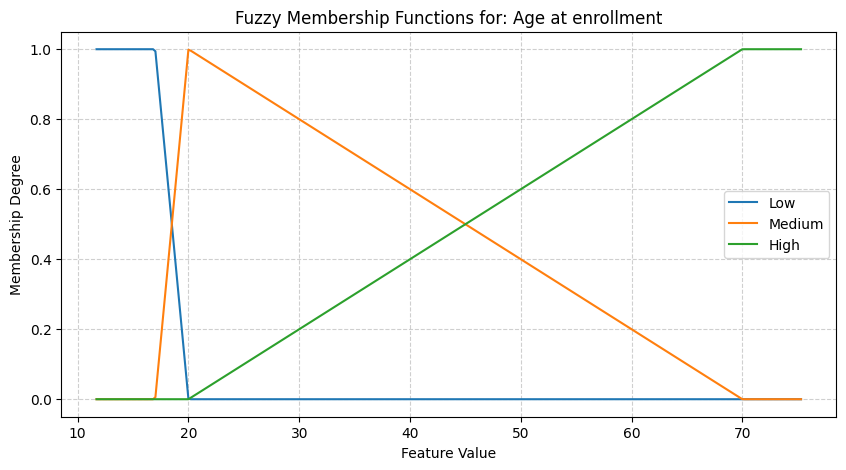

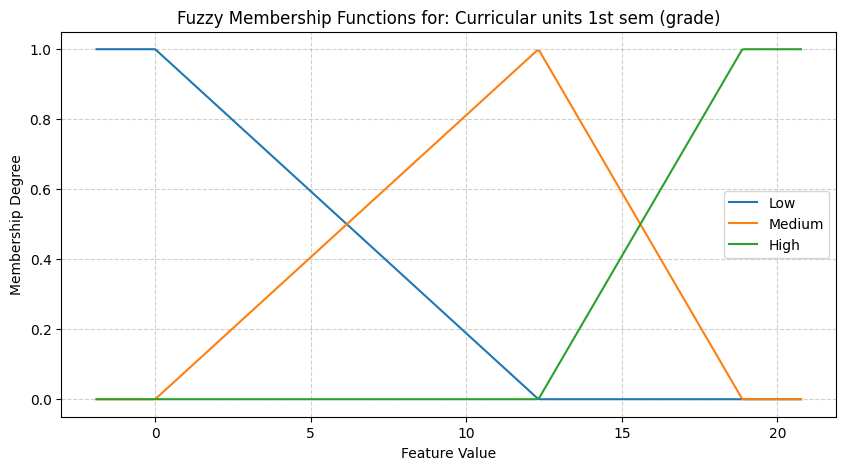

In [ ]:
def plot_membership_functions(feature_name, params_dict):
    """
    Plots the triangular membership functions for a given continuous feature.
    """
    if feature_name not in params_dict:
        print(f"Error: Parameters for feature '{feature_name}' not found.")
        return

    feature_params = params_dict[feature_name]
    # Determine the plot range based on all points defined for this feature
    all_points = [p[i] for p in feature_params.values() for i in range(3)]
    min_val = min(all_points)
    max_val = max(all_points)

    # Handle cases where the range is zero
    if max_val == min_val:
        x_range = np.linspace(min_val - 0.5, max_val + 0.5, 100) # Small range around the single value
    else:
        padding = (max_val - min_val) * 0.1 # Add some padding around the edges
        x_range = np.linspace(min_val - padding, max_val + padding, 300)

    plt.figure(figsize=(10, 5))
    plt.title(f'Fuzzy Membership Functions for: {feature_name}')
    plt.xlabel('Feature Value')
    plt.ylabel('Membership Degree')

    for set_name, points in feature_params.items():
        membership_values = [triangular_mf(x, points[0], points[1], points[2]) for x in x_range]
        plt.plot(x_range, membership_values, label=set_name)

    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim([-0.05, 1.05]) # Set Y-axis limits
    plt.show()

# --- Plotting for two continuous features ---
print("\n--- Plotting Membership Functions ---")
feature_to_plot_1 = 'Age at enrollment'
feature_to_plot_2 = 'Curricular units 1st sem (grade)'

if feature_to_plot_1 in mf_params_continuous:
    plot_membership_functions(feature_to_plot_1, mf_params_continuous)
else:
    print(f"Feature '{feature_to_plot_1}' not found among continuous features for plotting.")

if feature_to_plot_2 in mf_params_continuous:
     # For grades, we might want to consider only values > 0 or adjust the plot range
     # Here, we use parameters calculated from the full training data
    plot_membership_functions(feature_to_plot_2, mf_params_continuous)
else:
     print(f"Feature '{feature_to_plot_2}' not found among continuous features for plotting.")